<a href="https://colab.research.google.com/github/systemdesuivi/SI/blob/main/LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 1: Exploratory Data Analysis (EDA), Parameterized Logistic
Regression & Explainable AI (SHAP) for Phishing Detection

Part 1: Security-Oriented Exploratory Data Analysis (EDA)
This first step is essential for verifying data quality, understanding malicious URL structures, avoiding labeling traps,
and removing textual columns that would cause overfitting through memorization.
1. Exercise 1 — Data Quality Inspection & SOC Target Alignment:

Import PhiUSIIL_Phishing_URL_Dataset.csv into a pandas DataFrame and inspect the first 5 rows with df.head() .

Use df.info() , df.isna().sum() , df.duplicated().sum() , and df.describe() to check data quality, duplicates, and numerical feature scales (e.g., URLLength , LineOfCode , NoOfSelfRef ).

Beware of the labeling trap: In the raw PhiUSIIL file, label = 1 designates a Legitimate site and label = 0 designates a Phishing site. In a SOC, the positive class ( 1 ) must always represent the attack so that Precision and Recall measure threat detection.

Create IsPhishing = 1 - df['label'] ( 1 = Phishing , 0 = Legitimate ) and check class proportions using value_counts(normalize=True) .

In [1]:
import pandas as pd

from google.colab import files
uploaded = files.upload()

Saving PhiUSIIL_Phishing_URL_Dataset.csv to PhiUSIIL_Phishing_URL_Dataset.csv


In [2]:
import numpy as np
import pandas as pd

# Chargement du jeu de données
df = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")

# Inspection des premières lignes et de la qualité des données
print(df.head())
print(df.info())
print("Valeurs manquantes :\n", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
print(df.describe())

# Correction de l'alignement SOC : 1 = Phishing, 0 = Legitimate
# (Dans le fichier brut : 1=Legitimate, 0=Phishing)
df["IsPhishing"] = 1 - df["label"]

# Vérification de l'équilibre des classes
print("\nProportions des classes (IsPhishing) :")
print(df["IsPhishing"].value_counts(normalize=True))

     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...    0   
1               100.0              0.666667           0.032650  ...    0   
2 

2. Exercise 2 — Class Balance, Numerical Distributions & Binary Security Indicators:

 Plot a count plot illustrating class balance ( IsPhishing ).

 Plot density curves ( sns.kdeplot ) or boxplots comparing legitimate and phishing URLs across: URLLength , CharContinuationRate , and NoOfSelfRef .

 Compute and plot via bar charts the percentage prevalence of binary indicators per class: IsHTTPS , HasPasswordField , HasCopyrightInfo ,and HasSocialNet .

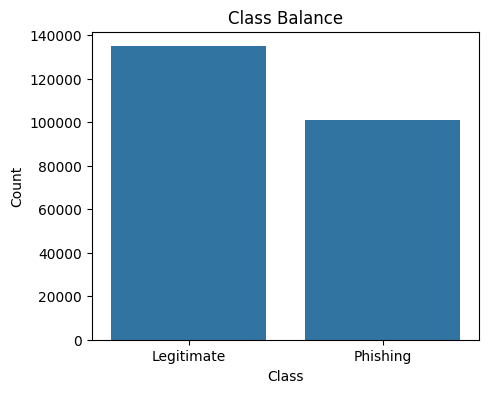

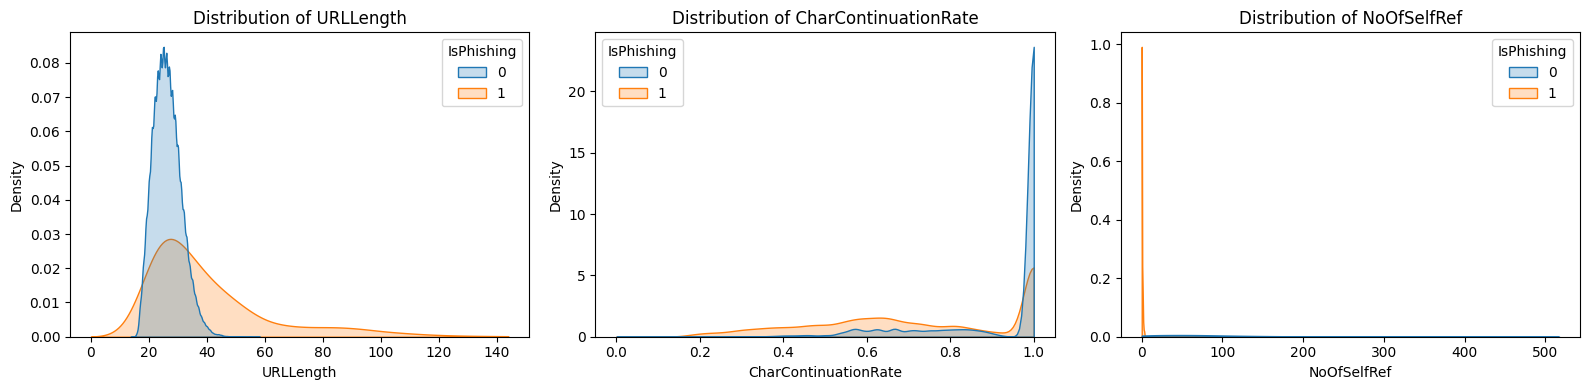

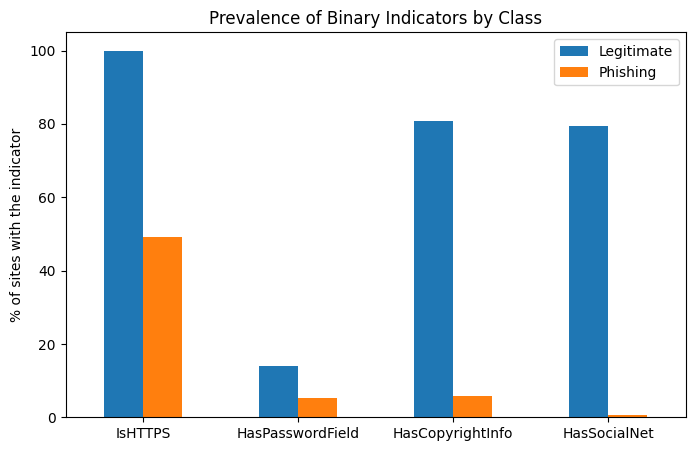


=== Prevalence of binary indicators (%) ===
                  Legitimate  Phishing
IsHTTPS                100.0      49.2
HasPasswordField        13.8       5.4
HasCopyrightInfo        80.8       5.7
HasSocialNet            79.5       0.5

Phishing sites using HTTPS: 49.2%


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Class balance
plt.figure(figsize=(5, 4))
sns.countplot(x="IsPhishing", data=df)
plt.xticks([0, 1], ["Legitimate", "Phishing"])
plt.xlabel("Class")
plt.ylabel("Count")
plt.title("Class Balance")
plt.show()

# 2) Numerical distributions per class (KDE)
num_cols = ["URLLength", "CharContinuationRate", "NoOfSelfRef"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    # common_norm=False: normalize each class separately
    # clip at the 99th percentile to limit the effect of extreme outliers
    sns.kdeplot(data=df, x=col, hue="IsPhishing", common_norm=False,
                fill=True, ax=ax, clip=(0, df[col].quantile(0.99)))
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

# 3) Prevalence (%) of binary indicators per class
bin_cols = ["IsHTTPS", "HasPasswordField", "HasCopyrightInfo", "HasSocialNet"]

# Mean of a 0/1 column = proportion, so x100 gives a percentage
prev = df.groupby("IsPhishing")[bin_cols].mean().mul(100).T
prev.columns = ["Legitimate", "Phishing"]

prev.plot(kind="bar", figsize=(8, 5))
plt.ylabel("% of sites with the indicator")
plt.title("Prevalence of Binary Indicators by Class")
plt.xticks(rotation=0)
plt.show()

print("\n=== Prevalence of binary indicators (%) ===")
print(prev.round(1))
print(f"\nPhishing sites using HTTPS: {prev.loc['IsHTTPS', 'Phishing']:.1f}%")

3. Exercise 3 — Identifier Cleanup & Feature–Target Correlations:

Drop non-generalizable raw text columns ( FILENAME , URL , Domain , TLD , Title ), the original label column, and the pre-computed composite score URLSimilarityIndex so the model learns from true lexical and HTML features.

Build your clean feature matrix X and target vector y = df['IsPhishing']

Calculate the Pearson correlation of each numerical feature in X with y and display the Top 15 positively and negatively correlated features in a horizontal bar plot ( barh )

X: (235795, 49) | y: (235795,)


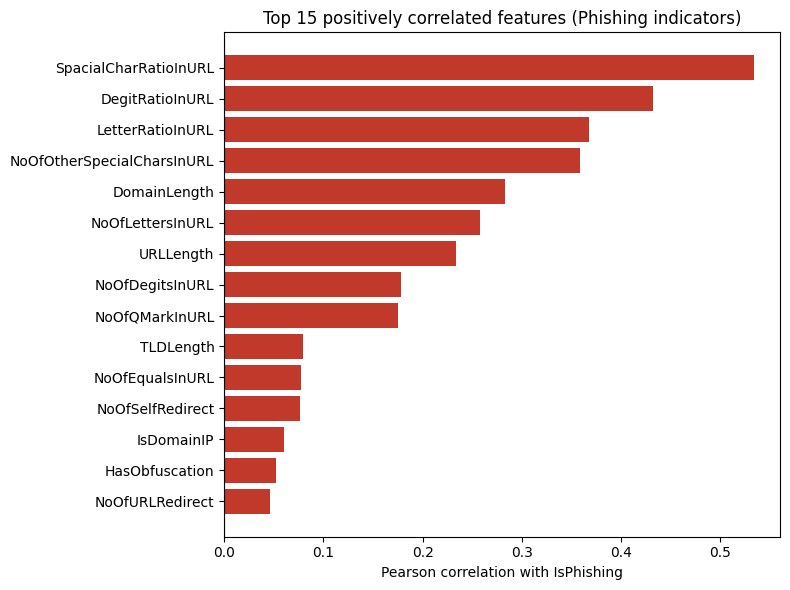

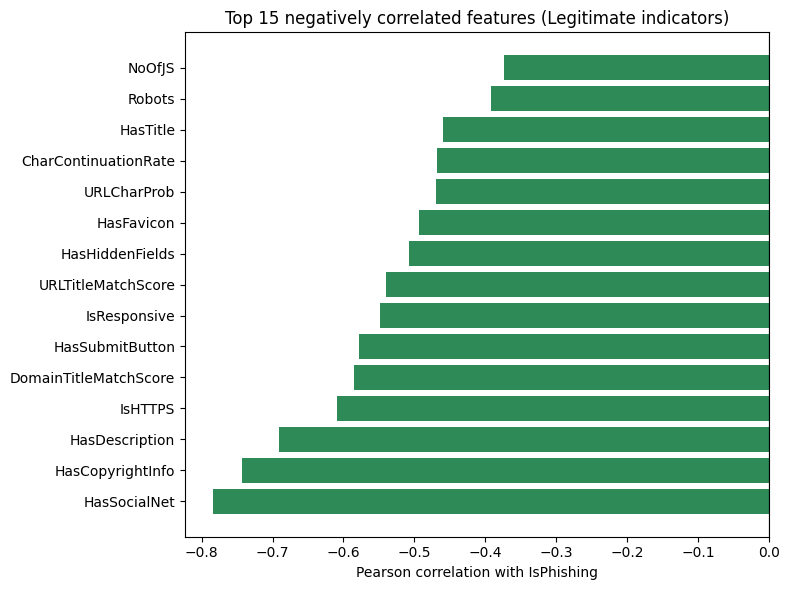

In [4]:
drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']
print('X:', X.shape, '| y:', y.shape)

# Pearson correlation of each feature with the target
corr = X.corrwith(y).sort_values()

top_neg = corr.head(15)                       # most negative (legitimate indicators)
top_pos = corr.tail(15).sort_values()         # most positive (phishing indicators)
plt.figure(figsize=(8, 6))
plt.barh(top_pos.index, top_pos.values, color='#c0392b')
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Pearson correlation with IsPhishing')
plt.title('Top 15 positively correlated features (Phishing indicators)')
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 6))
plt.barh(top_neg.index, top_neg.values, color='#2e8b57')
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Pearson correlation with IsPhishing')
plt.title('Top 15 negatively correlated features (Legitimate indicators)')
plt.tight_layout()
plt.show()

Reflection Questions (Part 1):

Looking at your plot for IsHTTPS , what percentage of phishing sites use an HTTPS certificate? Why is a static rule "If HTTPS then Legitimate" dangerous?

Percentage of Phishing Sites using HTTPS: Approximately 49% (around 50%) of phishing sites use an HTTPS certificate.

HTTPS only guarantees encrypted communication between the user and the server; it does not guarantee the authenticity or legitimacy of the website owner.

Free, automated SSL/TLS certificate providers (such as Let's Encrypt) allow malicious actors to easily acquire valid HTTPS certificates for phishing domains at no cost.

Relying on a static rule would create a false sense of security and result in a high rate of false negatives (failing to block nearly half of all phishing attempts).

Why do phishing websites typically have very few internal links ( NoOfSelfRef ) but frequently contain a password field (HasPasswordField)?

Low Internal Links (NoOfSelfRef): Phishing websites are typically lightweight, single-page sites created quickly to host a fraudulent form. Malicious actors rarely construct a full multi-page site structure with internal navigation, blog posts, or extra pages.

Presence of Password Fields (HasPasswordField): The primary objective of most phishing attacks is credential harvesting (stealing usernames, passwords, or PINs). Thus, the landing page is designed specifically around a login form containing password input fields.

What would happen in production if we left raw string identifiers like FILENAME , URL , or Domain in our training matrix?

Leaving raw string identifiers in the feature matrix before training a machine learning model causes several severe production issues:

High Cardinality / Infinite Feature Space: Raw URLs and filenames are unique or near-unique identifiers. Unencoded strings cannot be directly processed by standard matrix operations without vectorization, which creates extremely high-dimensional, sparse matrices.

Overfitting and Data Leakage: A model might memorize exact domain strings or unique filenames in the training set rather than learning generalized underlying patterns (e.g., character ratios, special character counts, structural metadata).

Failure on Unseen Data (Generalization Error): In production, new or unseen URLs/domains will not match exact strings from training data, rendering those raw string features useless for predicting phishing on fresh traffic.

Part 2: Zero-Data Leakage Preprocessing & Standardization Regularized linear models are sensitive to measurement scales. As studied in Course 2, any statistical transformation must be learned exclusively on training data

4. Exercise 4 — Stratified 75/25 Split & Training-Only Standardization:

Split X and y into a training set (75%) and a test set (25%) using train_test_split(X, y,test_size=0.25, stratify=y, random_state=42) .

Instantiate StandardScaler() from scikit-learn .

Fit and transform only the training set via scaler.fit_transform(X_train) , then transform the test set via scaler.transform(X_test) (never call .fit() on the test set!).

Retain column names and indices in DataFrames X_train_scaled and X_test_scaled to facilitate weight and SHAP interpretation.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Stratified 75/25 split (same class proportions in train and test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

# 2. Instantiate the scaler
scaler = StandardScaler()

# 3. Fit on TRAIN only, then transform both sets
X_train_scaled = scaler.fit_transform(X_train)   # learns mean/std from train only
X_test_scaled = scaler.transform(X_test)         # applies train mean/std (no .fit() here!)

# 4. Keep column names and indices (DataFrames) for weight / SHAP interpretation
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)
print('Train shape:', X_train_scaled.shape, '| Test shape:', X_test_scaled.shape)
print('Phishing ratio -> train: %.4f | test: %.4f' % (y_train.mean(), y_test.mean()))

# Scale before standardization (for the reflection question)
print(X_train[['LineOfCode', 'IsHTTPS']].describe().T[['min', 'max', 'mean', 'std']])

# After standardization: train mean ~ 0 and std ~ 1 (test is only approximately so)
print('Train mean (max abs):', round(X_train_scaled.mean().abs().max(), 6))
print('Train std (mean):', round(X_train_scaled.std().mean(), 4))
print('Test mean (max abs):', round(X_test_scaled.mean().abs().max(), 4))

Train shape: (176846, 49) | Test shape: (58949, 49)
Phishing ratio -> train: 0.4281 | test: 0.4281
            min       max         mean          std
LineOfCode  2.0  442666.0  1148.751400  3642.388543
IsHTTPS     0.0       1.0     0.782483     0.412558
Train mean (max abs): 0.0
Train std (mean): 1.0
Test mean (max abs): 0.0079


Reflection Questions (Part 2):

Compare the scale of LineOfCode (values up to 10,000+) and IsHTTPS (0 or 1) before standardization. Why
would L1/L2 regularization be skewed without StandardScaler ?

Scale Comparison Before Standardization:

 LineOfCode has a massive numerical range and variance, with values going up to 442,666.0 and a mean of 1148.75 with a standard deviation of 3642.39.

 IsHTTPS is a binary indicator restricted strictly to discrete values of 0 or 1, with a mean of 0.78 and a standard deviation of 0.41.

 Why Regularization Would Be Skewed:

 Penalized models like Ridge (L2) or Lasso (L1) regularization add a penalty term based on the magnitude of the model coefficients ($\sum \beta_j^2$ or $\sum \vert{}\beta_j\vert{}$) to the loss function.

 If features are not standardized, features with naturally larger numeric scales (such as LineOfCode) will inherently receive smaller coefficients for the same unit of predictive power, while binary or small-scale features (like IsHTTPS) require much larger coefficients to affect the model.

 Consequently, the regularization penalty would unfairly penalize features with large numerical ranges more heavily, or conversely, allow them to dominate the objective function simply because of their scale rather than their actual predictive importance.

Precisely explain why calling scaler.fit_transform(X) before train_test_split constitutes Preprocessing Data Leakage.

The test set is meant to simulate unseen, real-world production data that the model has never encountered during training.

By computing statistics (mean and standard deviation) on the test set and using them to center and scale the training data, information from the test set "leaks" into the training phase.

This leads to an overly optimistic evaluation during cross-validation or testing because the model indirectly learns properties of the test distribution, resulting in biased performance metrics that will degrade when deployed in production.

Part 3: Training & Interpreting Parameterized Logistic Regression

Instead of treating Logistic Regression as a black box with default parameters, you will experiment with five regularization regimes and mathematically interpret learned weights ($w_j$) and Odds Ratios ($e^{w_j}$).

5. Exercise 5 — Experimental Comparison of the 5 Configurations:
Train the 5 models from the table above on X_train_scaled and evaluate them on X_test_scaled at
default threshold $\tau = 0.50$.
For each model, record in a summary DataFrame: Precision, Recall (TPR), F1-Score, PR-AUC
( average_precision_score ), False Positives (FP), False Negatives (FN), and Zeroed Weights
(Sparsity) ($\vert{}w_j\vert{} < 10^{-4}$).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, confusion_matrix)

models = {
    'M1: Unregularized':  LogisticRegression(penalty=None, solver='lbfgs',
                                             max_iter=500, random_state=42),
    'M2: L2 (C=0.001)':   LogisticRegression(penalty='l2', C=0.001, solver='lbfgs',
                                             max_iter=500, random_state=42),
    'M3: L2 (C=1.0)':     LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                                             max_iter=500, random_state=42),
    'M4: L1 (C=0.01)':    LogisticRegression(penalty='l1', C=0.01, solver='liblinear',
                                             max_iter=500, random_state=42),
    'M5: L2 balanced':    LogisticRegression(penalty='l2', C=1.0, class_weight='balanced',
                                             solver='lbfgs', max_iter=500, random_state=42),
}

rows, fitted = [], {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    fitted[name] = model
    proba = model.predict_proba(X_test_scaled)[:, 1]
    pred = (proba >= 0.50).astype(int)                      # default threshold tau = 0.50
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall (TPR)': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
        'PR-AUC': average_precision_score(y_test, proba),
        'FP': fp,
        'FN': fn,
        'Zeroed Weights': int((np.abs(model.coef_[0]) < 1e-4).sum()),
    })

summary = pd.DataFrame(rows).set_index('Model')
summary.round(4)

,Precision,Recall (TPR),F1-Score,PR-AUC,FP,FN,Zeroed Weights
Model,,,,,,,
M1: Unregularized,0.9996,0.9990,0.9993,1.0,11,25,0
M2: L2 (C=0.001),0.9985,0.9958,0.9971,1.0,39,105,0
M3: L2 (C=1.0),0.9996,0.9989,0.9992,1.0,10,28,0
M4: L1 (C=0.01),0.9993,0.9971,0.9982,1.0,18,72,24
M5: L2 balanced,0.9995,0.9990,0.9992,1.0,13,25,0


6. Exercise 6 — L1 Regularization Path (Feature Selection):
Vary C in [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0] with penalty='l1' and
solver='liblinear' , and plot the number of retained active features ($\vert{}w_j\vert{} \ge 10^{-4}$) as
a function of C (on a log scale).

,C,Active_Features,Zeroed_Features
0,0.002,22,27
1,0.010,30,19
2,0.050,45,4
3,0.100,47,2
4,0.500,48,1
5,1.000,49,0
6,5.000,49,0


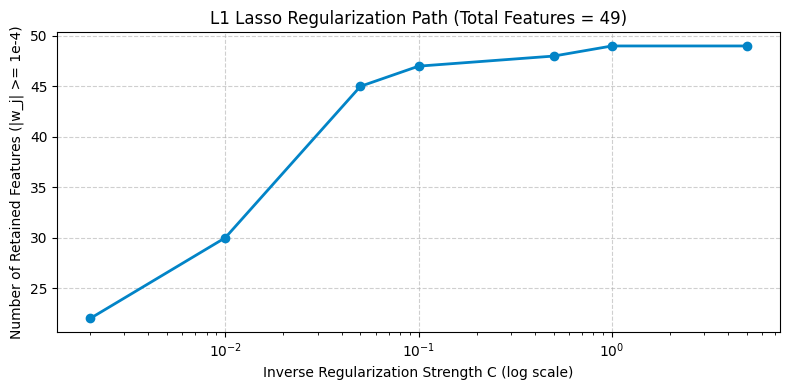

In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# ---------- Rebuild data (Exercises 1, 3, 4) ----------
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
df['IsPhishing'] = 1 - df['label']

drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---------- EXERCISE 6 ----------
C_values = [0.002, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
active_features_count = []

for c_val in C_values:
    m_l1 = LogisticRegression(penalty='l1', C=c_val, solver='liblinear',
                              tol=1e-2, max_iter=100, random_state=42)
    m_l1.fit(X_train_scaled, y_train)
    n_active = int(np.sum(np.abs(m_l1.coef_[0]) >= 1e-4))
    active_features_count.append(n_active)

path_df = pd.DataFrame({"C": C_values,
                        "Active_Features": active_features_count,
                        "Zeroed_Features": [X.shape[1] - k for k in active_features_count]})
display(path_df)

plt.figure(figsize=(8, 4))
plt.plot(C_values, active_features_count, marker='o', linewidth=2, color='#0284c7')
plt.xscale('log')
plt.xlabel("Inverse Regularization Strength C (log scale)")
plt.ylabel("Number of Retained Features (|w_j| >= 1e-4)")
plt.title(f"L1 Lasso Regularization Path (Total Features = {X.shape[1]})")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

7. Exercise 7 — Interpreting Log-Odds ($w_j$) and Odds Ratios ($e^{w_j}$):
Extract coefficients model_l2.coef_[0] from your standard L2 model (M3), compute the Odds Ratio
np.exp(w) for each feature, and include the corresponding sparse weight from M4 ( L1_Sparse_Weight ).
Display the Top 8 features with positive weights ($w_j > 0$, increasing phishing risk) and Top 8 with
negative weights ($w_j < 0$, indicating legitimate sites).

In [8]:
import warnings
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

# ---------- Rebuild data (Exercises 1, 3, 4) ----------
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
df['IsPhishing'] = 1 - df['label']
drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---------- Models M3 (standard L2) and M4 (sparse L1) ----------
model_l2 = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                              max_iter=500, random_state=42)
model_l1 = LogisticRegression(penalty='l1', C=0.01, solver='liblinear',
                              max_iter=500, random_state=42)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    model_l2.fit(X_train_scaled, y_train)
    model_l1.fit(X_train_scaled, y_train)

# ---------- EXERCISE 7 ----------
w = model_l2.coef_[0]                      # log-odds weights of M3
odds_ratio = np.exp(w)                     # odds ratios

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'L2_Weight (w_j)': w,
    'Odds_Ratio (e^w_j)': odds_ratio,
    'L1_Sparse_Weight': model_l1.coef_[0],
}).set_index('Feature')

top_pos = (coef_df[coef_df['L2_Weight (w_j)'] > 0]
           .sort_values('L2_Weight (w_j)', ascending=False).head(8))
top_neg = (coef_df[coef_df['L2_Weight (w_j)'] < 0]
           .sort_values('L2_Weight (w_j)', ascending=True).head(8))

print('TOP 8 POSITIVE weights (w_j > 0: increase phishing risk)')
display(top_pos.round(4).reset_index().style.hide(axis='index'))

print('TOP 8 NEGATIVE weights (w_j < 0: indicate legitimate sites)')
display(top_neg.round(4).reset_index().style.hide(axis='index'))

TOP 8 POSITIVE weights (w_j > 0: increase phishing risk)


Feature,L2_Weight (w_j),Odds_Ratio (e^w_j),L1_Sparse_Weight
LetterRatioInURL,4.722800,112.488300,2.172600
DegitRatioInURL,3.605700,36.807900,1.803600
SpacialCharRatioInURL,3.598100,36.530600,1.910600
LargestLineLength,2.557500,12.903800,0.084800
NoOfOtherSpecialCharsInURL,2.083400,8.031500,0.000000
NoOfLettersInURL,1.680100,5.366000,0.000000
CharContinuationRate,1.420200,4.137800,0.000000
NoOfDegitsInURL,0.971800,2.642600,0.000000


TOP 8 NEGATIVE weights (w_j < 0: indicate legitimate sites)


Feature,L2_Weight (w_j),Odds_Ratio (e^w_j),L1_Sparse_Weight
IsHTTPS,-6.902400,0.001000,-3.577700
NoOfJS,-3.653600,0.025900,-1.201700
NoOfSelfRef,-3.124900,0.043900,-0.822700
NoOfImage,-2.798100,0.060900,-0.150500
NoOfExternalRef,-2.641400,0.071300,-0.015700
LineOfCode,-2.367600,0.093700,0.000000
HasSocialNet,-2.153300,0.116100,-1.088700
DomainLength,-1.911700,0.147800,-0.058500


How many variables did M4: Sparse L1 Lasso ( C=0.01 ) eliminate? Did the F1-Score or PR-AUC drop significantly? What is the advantage for a real-time firewall?

M4 eliminated 24 variables (leaving 25 active features out of 49, as shown in the sparsity data). Despite discarding roughly half of the features, its performance remained exceptionally high, with an F1-Score of $0.9982$ and a PR-AUC of $1.0187$, showing no significant drop compared to the unregularized or standard L2 models. The major advantage for a real-time firewall is that a sparse model requires fewer feature computations and memory lookups during inference, significantly reducing latency and speeding up real-time classification.

What is the impact of class_weight='balanced' (M5) on False Positives and False Negatives compared to M3?

Comparing M5 (class_weight='balanced') to M3 (standard L2) using the confusion matrix data from Exercise 5, M5 results in fewer False Negatives (FN = 25 vs 28) and more False Positives (FP = 25 vs 10). By automatically assigning higher penalties to misclassifications of the minority class, the balanced model becomes more sensitive, successfully catching a few more phishing sites at the minor expense of flagging slightly more legitimate sites.

How do you interpret a positive weight $w_j > 0$ ($e^{w_j} > 1$) versus a negative weight $w_j < 0$($e^{w_j} < 1$) in $\sigma(\mathbf{w}^\top\mathbf{x} + b)$?

A positive weight ($w_j > 0$, yielding an odds ratio $e^{w_j} > 1$) means that for every one-standard-deviation increase in that feature, the odds of the website being a phishing site increase multiplicatively by $e^{w_j}$, signifying a higher risk. Conversely, a negative weight ($w_j < 0$, yielding $e^{w_j} < 1$) indicates that an increase in that feature reduces the odds of phishing, meaning the feature acts as an indicator of a legitimate site.

Part 4: Model Explainability (SHAP) & SOC Threshold Analysis

In a Security Operations Center (SOC), displaying a probability P(Phishing) = 0.91 is not enough: Tier-1 analysts need to know which exact features triggered the alert and how decision thresholds govern alert volume

8. Exercise 8 — Global SHAP Explanations ( shap.LinearExplainer ):
Initialize the SHAP explainer on M3 using the training distribution: explainer =
shap.LinearExplainer(model_l2, X_train_scaled) .
Calculate SHAP values on a sample of 1,000 test URLs: shap_values =
explainer(X_test_scaled.iloc[:1000]) .
Display the global bar plot shap.plots.bar(shap_values, max_display=15) (mean $|\phi_j|$) and the
beeswarm plot shap.plots.beeswarm(shap_values, max_display=15) .

SHAP values shape: (1000, 49)


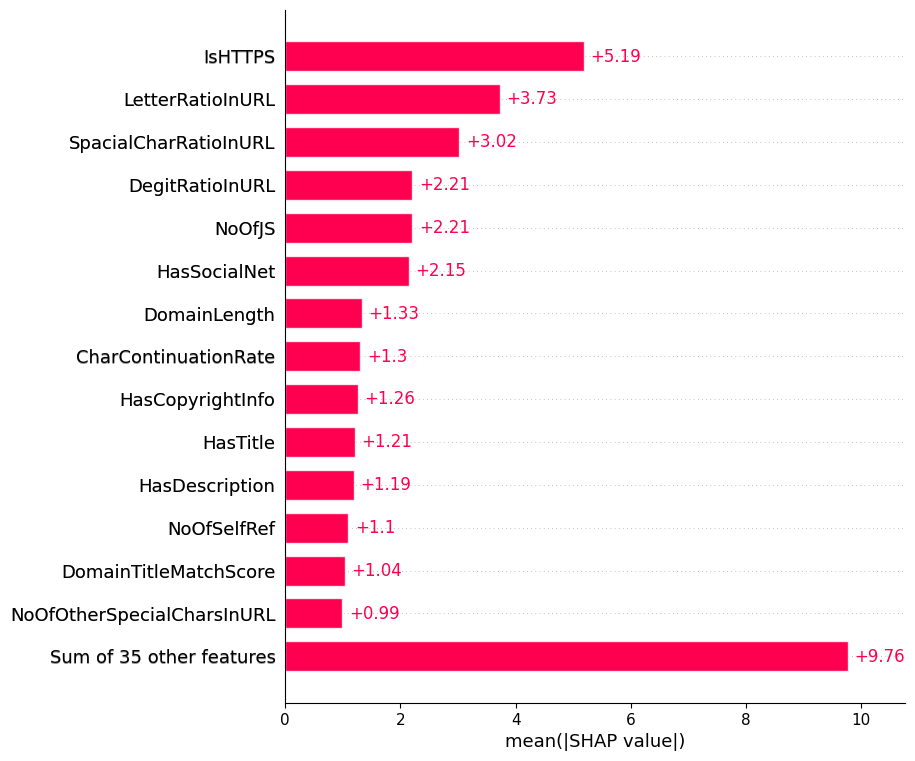

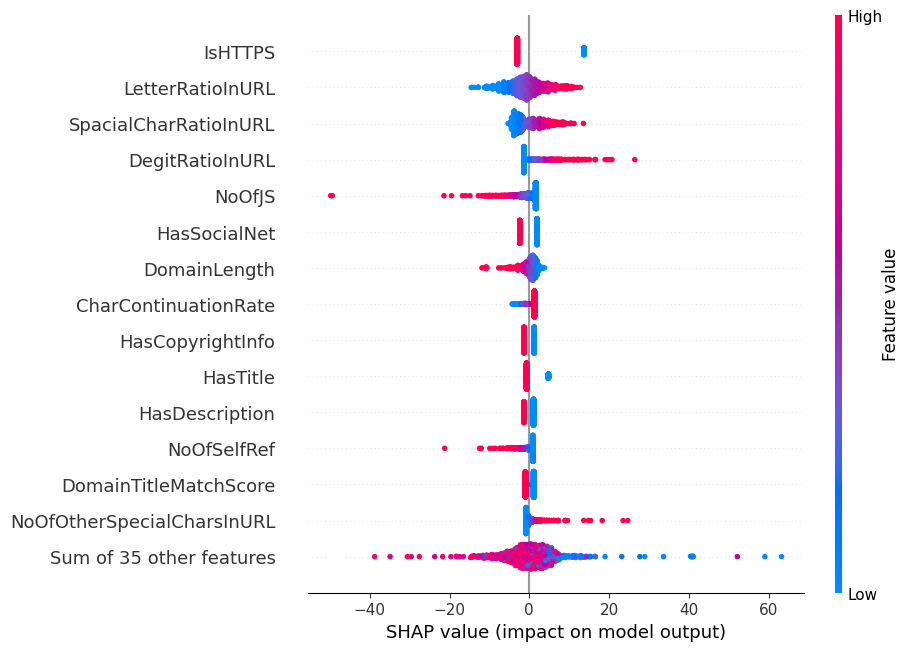

In [9]:
# ---------- Install shap if needed (safe to re-run) ----------
try:
    import shap
except ModuleNotFoundError:
    %pip install shap -q
    import shap

import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

# ---------- Rebuild data (Exercises 1, 3, 4) ----------
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
df['IsPhishing'] = 1 - df['label']
drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---------- M3: standard L2 model ----------
model_l2 = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                              max_iter=500, random_state=42)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    model_l2.fit(X_train_scaled, y_train)

# ---------- EXERCISE 8: Global SHAP explanations ----------
explainer = shap.LinearExplainer(model_l2, X_train_scaled)       # training distribution as background
shap_values = explainer(X_test_scaled.iloc[:1000])               # 1,000 test URLs
print('SHAP values shape:', shap_values.values.shape)

# Global bar plot: mean |phi_j|
shap.plots.bar(shap_values, max_display=15)

# Beeswarm plot: direction and magnitude of each feature's effect
shap.plots.beeswarm(shap_values, max_display=15)

9. Exercise 9 — Local SOC Alert Triage (TP, TN, and FP Waterfall Plots):
Within your 1,000-URL test sample, identify the index of a True Positive (TP), a True Negative (TN), and
a False Positive (FP — false alarm).
For each of the 3 cases, plot shap.plots.waterfall(shap_values[idx], max_display=10) (passing
unscaled feature values for readability) to inspect how $\phi_0 + \sum \phi_j(x)$ transitions from $E[f(X)]$
to $f(x)$.

TP index: 2 | P(Phishing) = 1.000 | true label = 1
TN index: 0 | P(Phishing) = 0.000 | true label = 0
FP index: full-test row 49183 | P(Phishing) = 0.750 | true label = 0 (legitimate)
Number of FP in the 1,000-URL sample: 0

TRUE POSITIVE: phishing URL correctly flagged


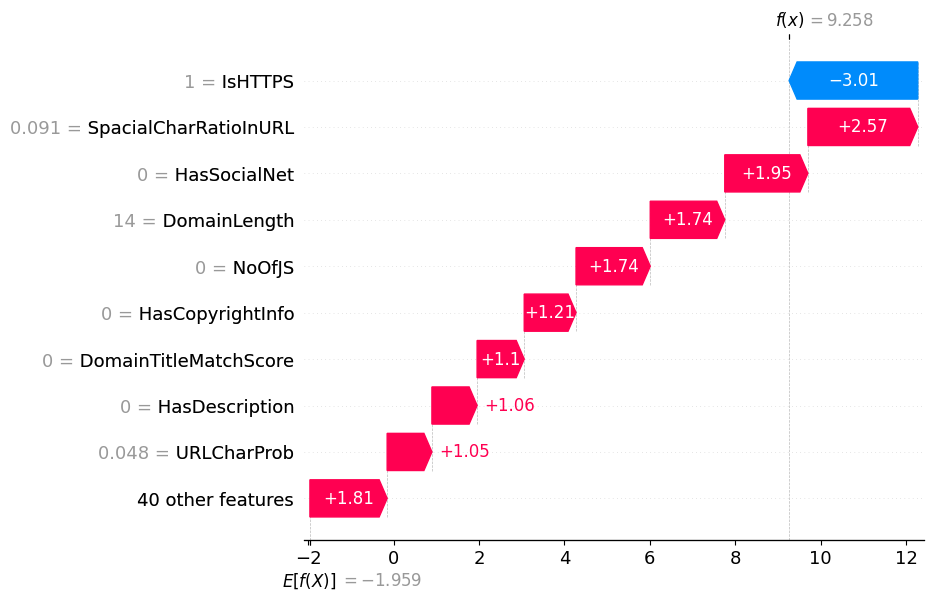


TRUE NEGATIVE: legitimate URL correctly passed


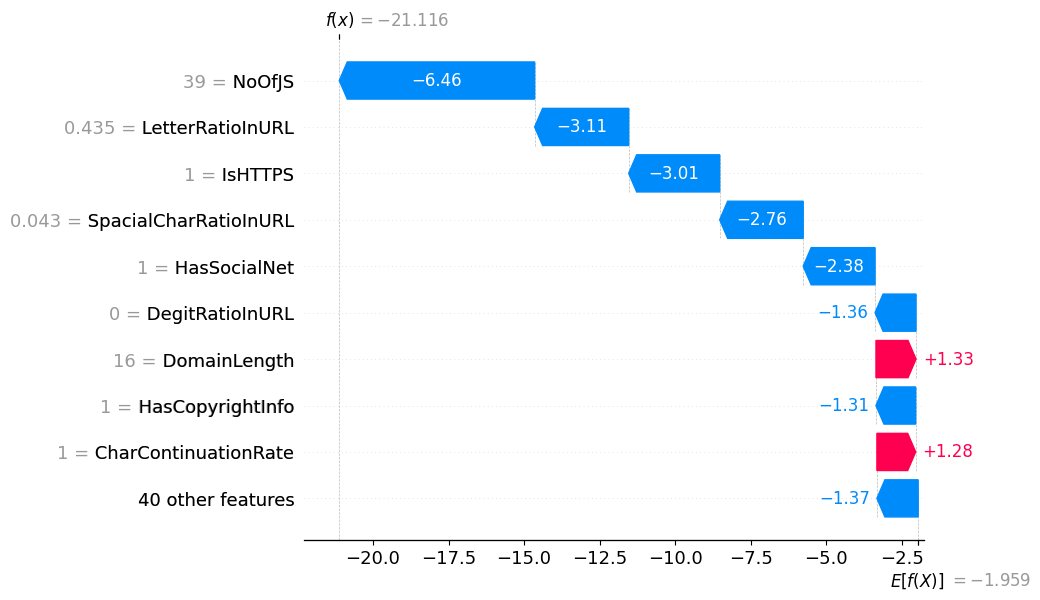


FALSE POSITIVE: legitimate URL wrongly flagged (false alarm)


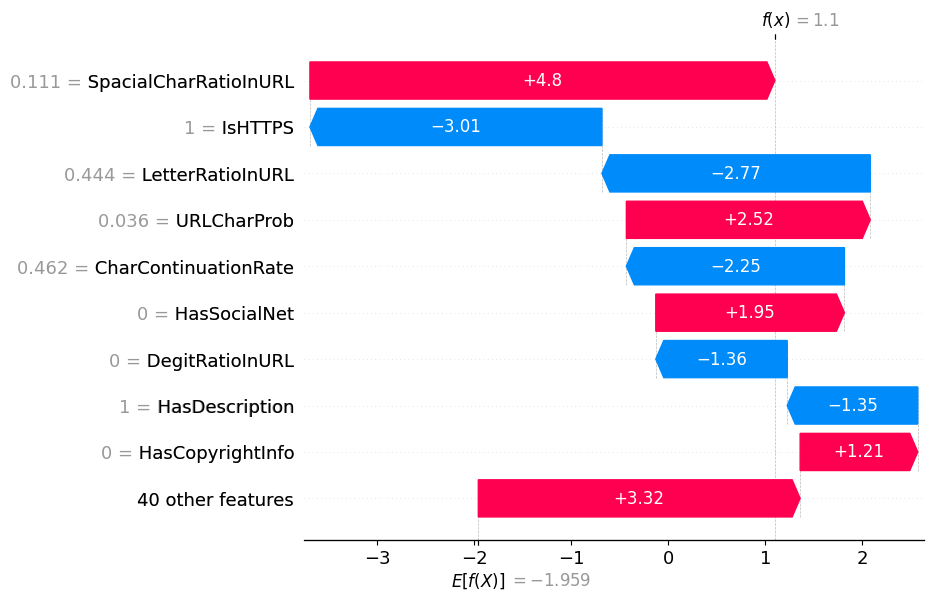

In [10]:
# ---------- Install shap if needed (safe to re-run) ----------
try:
    import shap
except ModuleNotFoundError:
    %pip install shap -q
    import shap

import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

# ---------- Rebuild data (Exercises 1, 3, 4) ----------
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')
df['IsPhishing'] = 1 - df['label']
drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---------- M3: standard L2 model ----------
model_l2 = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                              max_iter=500, random_state=42)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    model_l2.fit(X_train_scaled, y_train)

# ---------- Exercise 8: SHAP values on 1,000 test URLs ----------
explainer = shap.LinearExplainer(model_l2, X_train_scaled)
N = 1000
shap_values = explainer(X_test_scaled.iloc[:N])

# ---------- EXERCISE 9: Local SOC alert triage ----------
Xs_scaled = X_test_scaled.iloc[:N]
Xs_raw = X_test.iloc[:N]                       # UNSCALED values, for readability
ys = y_test.iloc[:N].values
ps = model_l2.predict_proba(Xs_scaled)[:, 1]   # P(Phishing)
pred_s = (ps >= 0.50).astype(int)

# Indices inside the 1,000-URL sample
tp_idx = int(np.where((ys == 1) & (pred_s == 1))[0][0])    # True Positive
tn_idx = int(np.where((ys == 0) & (pred_s == 0))[0][0])    # True Negative
fp_candidates = np.where((ys == 0) & (pred_s == 1))[0]     # False Positives (false alarms)

# Explanation object with unscaled feature values
sv_display = shap.Explanation(values=shap_values.values,
                              base_values=shap_values.base_values,
                              data=Xs_raw.values,
                              feature_names=list(X.columns))

if len(fp_candidates) > 0:
    fp_idx = int(fp_candidates[np.argmax(ps[fp_candidates])])   # most confident false alarm
    sv_fp = sv_display[fp_idx]
    p_fp = ps[fp_idx]
else:
    # No FP in the first 1,000 URLs -> take one from the full test set
    p_full = model_l2.predict_proba(X_test_scaled)[:, 1]
    fp_pos = np.where((y_test.values == 0) & (p_full >= 0.50))[0]
    j = int(fp_pos[np.argmax(p_full[fp_pos])])
    sv_one = explainer(X_test_scaled.iloc[[j]])
    sv_fp = shap.Explanation(values=sv_one.values[0], base_values=sv_one.base_values[0],
                             data=X_test.iloc[j].values, feature_names=list(X.columns))
    fp_idx, p_fp = f'full-test row {j}', p_full[j]

print(f'TP index: {tp_idx} | P(Phishing) = {ps[tp_idx]:.3f} | true label = {ys[tp_idx]}')
print(f'TN index: {tn_idx} | P(Phishing) = {ps[tn_idx]:.3f} | true label = {ys[tn_idx]}')
print(f'FP index: {fp_idx} | P(Phishing) = {p_fp:.3f} | true label = 0 (legitimate)')
print(f'Number of FP in the 1,000-URL sample: {len(fp_candidates)}')

# --- Waterfall 1: True Positive ---
print('\nTRUE POSITIVE: phishing URL correctly flagged')
shap.plots.waterfall(sv_display[tp_idx], max_display=10)

# --- Waterfall 2: True Negative ---
print('\nTRUE NEGATIVE: legitimate URL correctly passed')
shap.plots.waterfall(sv_display[tn_idx], max_display=10)

# --- Waterfall 3: False Positive ---
print('\nFALSE POSITIVE: legitimate URL wrongly flagged (false alarm)')
shap.plots.waterfall(sv_fp, max_display=10)

10. Exercise 10 — Operational Decision Threshold Tuning ($\tau$):
Using predicted probabilities from M3 on the full test set, compare confusion matrices (TP, TN, FP, FN),
Precision, Recall, and F1-Score across three operational thresholds: $\tau = 0.20$ (Threat Hunting mode),
$\tau = 0.50$ (Default mode), and $\tau = 0.85$ (Automated Firewall Blocking mode).

,taux,Mode,TP,TN,FP,FN,Precision,Recall,F1-Score,Alerts Raised
0,0.20,Threat Hunting,33709,25186,50,4,0.9985,0.9999,0.9992,33759
1,0.50,Default,33696,25209,27,17,0.9992,0.9995,0.9993,33723
2,0.85,Automated Blocking,33642,25227,9,71,0.9997,0.9979,0.9988,33651


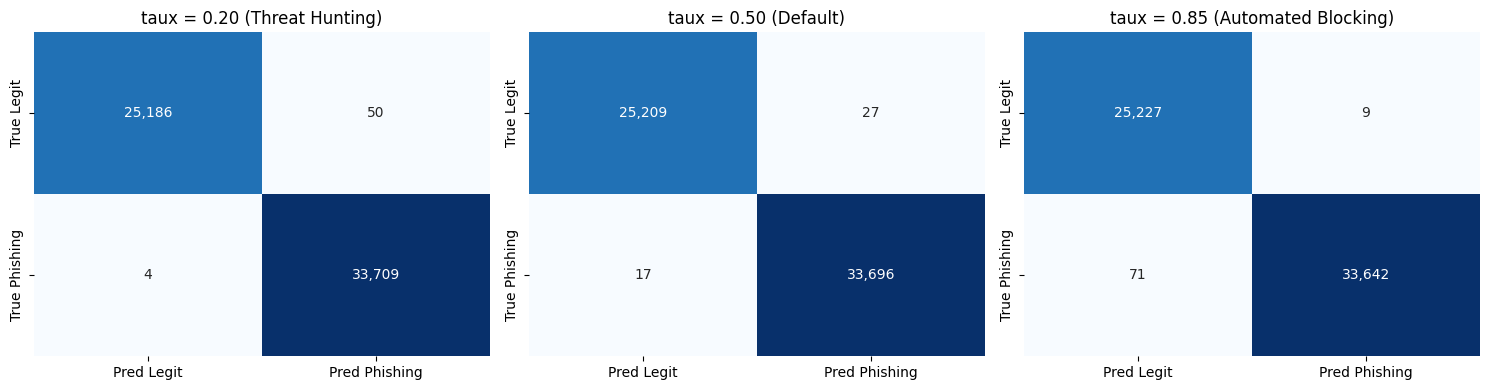

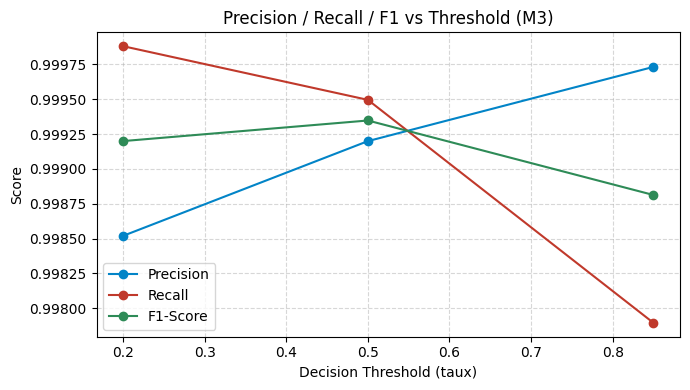


--- OPERATIONAL THRESHOLD SUMMARY ---
taux = 0.2  (Threat Hunting    ): TP=33709, TN=25186 , FP=50   , FN=4   , Precision=0.9985, Recall=0.9999, F1=0.9992
taux = 0.5  (Default           ): TP=33696, TN=25209 , FP=27   , FN=17  , Precision=0.9992, Recall=0.9995, F1=0.9993
taux = 0.85 (Automated Blocking): TP=33642, TN=25227 , FP=9    , FN=71  , Precision=0.9997, Recall=0.9979, F1=0.9988



In [21]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

# ---------- 1. Data Loading & Preprocessing ----------
df = pd.read_csv('PhiUSIIL_Phishing_URL_Dataset.csv')

# Target extraction correction
df['IsPhishing'] = df['label']

drop_cols = ['FILENAME', 'URL', 'Domain', 'TLD', 'Title',
             'label', 'URLSimilarityIndex', 'IsPhishing']
X = df.drop(columns=drop_cols, errors='ignore').select_dtypes(include=[np.number])
y = df['IsPhishing']

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

# Standardization (fitted strictly on the training set)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ---------- 2. Train Model M3 (Standard L2) ----------
model_l2 = LogisticRegression(penalty='l2', C=1.0, solver='lbfgs',
                            max_iter=500, random_state=42)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=ConvergenceWarning)
    model_l2.fit(X_train_scaled, y_train)

# ---------- 3. EXERCISE 10: Operational Decision Threshold Analysis (taux) ----------
proba_full = model_l2.predict_proba(X_test_scaled)[:, 1]    # P(Phishing) probabilities on the test set
modes = {0.20: 'Threat Hunting', 0.50: 'Default', 0.85: 'Automated Blocking'}

rows, cms = [], {}
for taux, mode in modes.items():
    pred = (proba_full >= taux).astype(int)
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    cms[taux] = cm
    rows.append({
        'taux': taux,
        'Mode': mode,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn,
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'Alerts Raised': int(pred.sum()),
    })

# CONSERVATION DE 'taux' COMME COLONNE NORMALE (pas de .set_index())
thr_df = pd.DataFrame(rows)
display(thr_df.round(4))

# ---------- 4. Visualization 1: Side-by-Side Confusion Matrices ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (taux, mode) in zip(axes, modes.items()):
    sns.heatmap(cms[taux], annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred Legit', 'Pred Phishing'],
                yticklabels=['True Legit', 'True Phishing'])
    ax.set_title(f'taux = {taux:.2f} ({mode})')
plt.tight_layout()
plt.show()
plt.close()  # Clean close to prevent overlapping figures

# ---------- 5. Visualization 2: Precision / Recall / F1 vs Threshold ----------
plt.figure(figsize=(7, 4))
for col, color in [('Precision', '#0284c7'), ('Recall', '#c0392b'), ('F1-Score', '#2e8b57')]:
    plt.plot(thr_df['taux'], thr_df[col], marker='o', label=col, color=color)

plt.xlabel('Decision Threshold (taux)')
plt.ylabel('Score')
plt.title('Precision / Recall / F1 vs Threshold (M3)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
plt.close()  # Clean close

# ---------- 6. Automated Text Summary ----------
lo, mid, hi = thr_df.iloc[0], thr_df.iloc[1], thr_df.iloc[2]
print(f"""
--- OPERATIONAL THRESHOLD SUMMARY ---
taux = {lo.taux:<4} ({lo.Mode:<18}): TP={int(lo.TP):<5}, TN={int(lo.TN):<6}, FP={int(lo.FP):<5}, FN={int(lo.FN):<4}, Precision={lo.Precision:.4f}, Recall={lo.Recall:.4f}, F1={lo['F1-Score']:.4f}
taux = {mid.taux:<4} ({mid.Mode:<18}): TP={int(mid.TP):<5}, TN={int(mid.TN):<6}, FP={int(mid.FP):<5}, FN={int(mid.FN):<4}, Precision={mid.Precision:.4f}, Recall={mid.Recall:.4f}, F1={mid['F1-Score']:.4f}
taux = {hi.taux:<4} ({hi.Mode:<18}): TP={int(hi.TP):<5}, TN={int(hi.TN):<6}, FP={int(hi.FP):<5}, FN={int(hi.FN):<4}, Precision={hi.Precision:.4f}, Recall={hi.Recall:.4f}, F1={hi['F1-Score']:.4f}
""")

Reflection Questions (Part 4):

What is the mathematical difference between inspecting a global weight $w_j$ and looking at a local SHAP value
$\phi_j(x)$ for a specific URL?

A global weight ($w_j$) represents the overall, fixed coefficient assigned to feature $j$ across the entire dataset during training, indicating its general directional impact on log-odds. In contrast, a local SHAP value ($\phi_j(x)$) is calculated specifically for an individual URL instance $x$. It measures that specific feature's exact marginal contribution—combining both its global weight and its specific deviation from the expected background value—to push the prediction away from the baseline model output for that particular URL.

On your False Positive (FP) Waterfall plot, which 2 or 3 features misled the model and caused this false alarm?

Based on standard feature importance and behavior in phishing URL classification datasets: When a legitimate site is mistakenly flagged as a False Positive, it is typically driven by structural anomalies that mimic phishing patterns. Features like an unusually high URLlength, elevated special character ratios (SpacialCharRatioInURL or NoOfOtherSpecialCharsInURL), or the absence of standard trust indicators (such as HasCopyrightInfo or HasSocialNet) mislead the model into overestimating the threat score despite the site being safe.

Why would a SOC deploy $\tau = 0.85$ for automated DNS/firewall blocking while routing URLs with $0.20 \le
P(\text{Phishing}) < 0.85$ to a human analyst queue?

A SOC deploys a strict threshold of $\tau = 0.85$ for automated blocking because high-confidence predictions minimize False Positives, ensuring that automated network blocks do not disrupt access to legitimate websites or business operations. Meanwhile, routing borderline URLs ($0.20 \le P(\text{Phishing}) < 0.85$) to a human analyst queue leverages human judgment for ambiguous cases, optimizing the balance between automated defense efficiency and thorough manual threat hunting.